## Programa13.Variables Cuantitativas
![logo ITQ](img/ITQ.png)

**Nombre:** Emerson Suquillo

**Fecha:** 25-11-2026


**link del repositorio:** <a href="https://github.com/Emerson94stif/FundamentosMachineLeaning26-27/blob/main/Programa9.ValidacionCruzada2.ipynb">Link Repositorio</a> 


**Variables cuantitativas:** Son aquellas que se expresan numéricamente y permiten realizar operaciones matemáticas, como medir edad, peso, ingresos o temperatura.


**Formula:**

In [2]:
#Importamos las librerias

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
# creamos los datos
X= np.array([0.5,23,0.3,4.5, 0.3, 0.5,-28,-50,60,-100,-10,-11,13,19,1,9])
print(X)

[   0.5   23.     0.3    4.5    0.3    0.5  -28.   -50.    60.  -100.
  -10.   -11.    13.    19.     1.     9. ]


In [4]:
#calculamos medidas de tendencia central
media= np.mean(X)
mediana=np.median(X)
moda,_ =stats.mode(X)
print(" La media de los datos es:", media) # la suma de todos los datos dividido para la cantidad
print(" La media de los datos es:", mediana)# lamitad de todos los datos 
print(" La media de los datos es:", moda)  # los datos que mas se repiten


 La media de los datos es: -4.24375
 La media de los datos es: 0.5
 La media de los datos es: 0.3


In [5]:
#Calculamos madidas de posicion
Q1 = np.percentile(X,25)
Q3 = np.percentile(X,75)
RIC= Q3 - Q1
lim_inf =Q1 - 1.5*RIC
lim_sup= Q3 + 1.5*RIC
print(" limite inferior:",lim_inf)
print(" limite superior:",lim_sup)
print(" limite inferior:",RIC)

 limite inferior: -40.625
 limite superior: 40.375
 limite inferior: 20.25


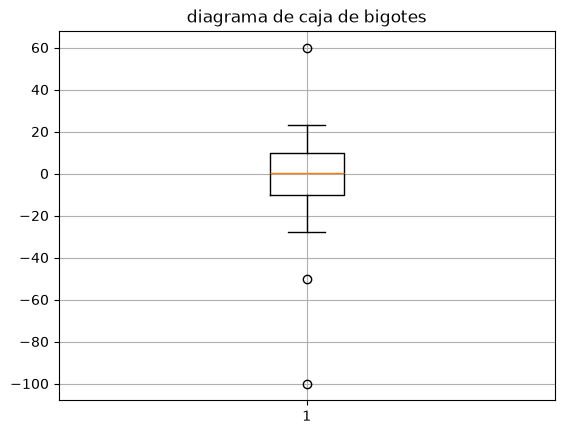

In [6]:
# Dibujamos una caja de bigotes para ver los datos
plt.boxplot(X)
plt.grid()
plt.title("diagrama de caja de bigotes")
plt.show()

In [13]:
# Medidas de dispersión
desvest = np.std(X)
print('Desviación típica: ', desvest)
print('Varianza: ', desvest**2)

Desviación típica:  33.521242681880096
Varianza:  1123.6737109375


In [15]:
# Medidas de distribución
asimetria = stats.skew(X)
curtosis = stats.kurtosis(X, fisher=True) # https://docs.scipy.org/doc/scipy/
#eference/generated/scipy.stats.kurtosis.html
print('Asimetría ', np.round(asimetria, 4))
print('Curtosis ', np.round(curtosis, 4))
if curtosis>0:
    print('Distribución Leptocúrtica')
elif curtosis<0:
    print('Distribución Platicúrtica')
else:
    print('Distribución Mesocúrtica')

Asimetría  -1.1302
Curtosis  2.2858
Distribución Leptocúrtica


In [21]:
# Cargar el set de datos de Iris
from sklearn import datasets
from pprint import pprint
from scipy.stats import skew, kurtosis
iris = datasets.load_iris()
#pprint(iris)
X = iris.data
y = iris.target
# ¿Qué tipo de asimetría se observa en la variable "longitud del pétalo"?
#???
longitud_petalo = X[:, 2]
asimetria = skew(longitud_petalo)
print("Asimetría:", asimetria)
if asimetria > 0:
    print("La variable presenta asimetría positiva (sesgo hacia la derecha).")
elif asimetria < 0:
    print("La variable presenta asimetría negativa (sesgo hacia la izquierda).")
else:
    print("La variable tiene una distribución simétrica.")
# ¿A qué tipo de distribución se ajusta la variable "ancho del sépalo", según␣
#↪su curtosis?
#???
ancho_sepalo = X[:, 1]
curt = kurtosis(ancho_sepalo)
print("Curtosis:", curt)
if curt > 0:
    print("La distribución es leptocúrtica.")
elif curt < 0:
    print("La distribución es platicúrtica.")
else:
    print("La distribución es mesocúrtica.")

Asimetría: -0.2721276664567214
La variable presenta asimetría negativa (sesgo hacia la izquierda).
Curtosis: 0.18097631752246768
La distribución es leptocúrtica.


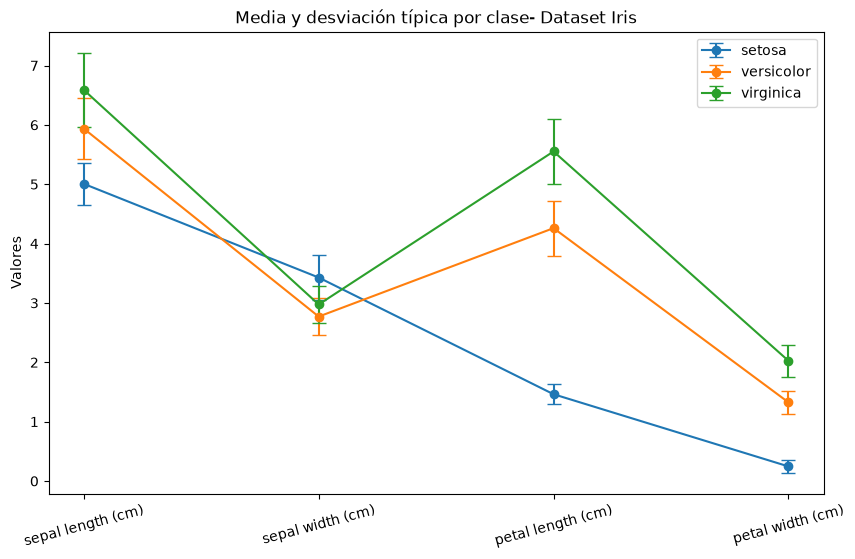

In [23]:
# EJERCICIO EXTRA SOBRE EL DATASET DE IRIS
# Extraer la media y la desviación típica de cada variable en función de la␣
#clase y representarlo en un gráfico (plt.errorbar)
# Nombres de variables
variables = iris.feature_names
# Clases
clases = np.unique(y)
# Crear figura
plt.figure(figsize=(10,6))
# Recorrer cada clase
for clase in clases:
# Filtrar datos por clase
    datos_clase = X[y == clase]
# Calcular media
    media = np.mean(datos_clase, axis=0)
# Calcular desviación típica
    desviacion = np.std(datos_clase, axis=0)
# Graficar con barras de error
    plt.errorbar(
        range(len(variables)),
        media,
        yerr=desviacion,
        marker='o',
        capsize=5,
        label=iris.target_names[clase]
    )
# Configuración del gráfico
plt.xticks(range(len(variables)), variables, rotation=15)
plt.ylabel("Valores")
plt.title("Media y desviación típica por clase- Dataset Iris")
plt.legend()
plt.show()